In [1]:
%pip install pandas numpy matplotlib seaborn scikit-learn xgboost openpyxl jupyter streamlit

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

import pickle
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
%matplotlib inline

In [9]:
df = pd.read_csv(r'C:\Users\User\OneDrive\Documents\Klasifikasi_Cuaca_Kolkata_XGBoost\kolkata_weather_jan_june_2026.csv')
print('Shape data:', df.shape)
df.head()

Shape data: (1827, 17)


,time,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunrise,sunset,sunshine_duration,city,latitude,longitude
0,2021-06-30,65,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,2021-06-30T04:55,2021-06-30T18:25,20837.76,Kolkata,22.5726,88.3639
1,2021-07-01,63,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,2021-07-01T04:55,2021-07-01T18:25,21439.24,Kolkata,22.5726,88.3639
2,2021-07-02,63,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,2021-07-02T04:56,2021-07-02T18:25,12291.52,Kolkata,22.5726,88.3639
3,2021-07-03,63,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,2021-07-03T04:56,2021-07-03T18:25,29486.65,Kolkata,22.5726,88.3639
4,2021-07-04,63,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,2021-07-04T04:56,2021-07-04T18:25,41145.46,Kolkata,22.5726,88.3639


In [10]:
# Menampilkan ukuran dataset
print("Jumlah baris dan kolom:", df.shape)
print("Jumlah baris:", df.shape[0])
print("Jumlah kolom:", df.shape[1])

Jumlah baris dan kolom: (1827, 17)
Jumlah baris: 1827
Jumlah kolom: 17


In [11]:
# Menampilkan informasi dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1827 entries, 0 to 1826
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   time                         1827 non-null   object 
 1   weather_code                 1827 non-null   int64  
 2   temperature_2m_mean          1827 non-null   float64
 3   temperature_2m_max           1827 non-null   float64
 4   temperature_2m_min           1827 non-null   float64
 5   precipitation_sum            1827 non-null   float64
 6   rain_sum                     1827 non-null   float64
 7   precipitation_hours          1827 non-null   float64
 8   wind_speed_10m_max           1827 non-null   float64
 9   wind_gusts_10m_max           1827 non-null   float64
 10  wind_direction_10m_dominant  1827 non-null   int64  
 11  sunrise                      1827 non-null   object 
 12  sunset                       1827 non-null   object 
 13  sunshine_duration 

In [12]:
# Menampilkan ringkasan statistik
df.describe()

,weather_code,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration,latitude,longitude
count,1827.000000,1827.00000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1827.000000,1.827000e+03,1.827000e+03
mean,34.143952,26.26486,31.099234,22.477066,5.429119,5.429119,4.952928,13.782157,30.756596,192.212917,33185.460542,2.257260e+01,8.836390e+01
std,28.997216,4.05022,3.924558,4.847343,9.550693,9.550693,6.275264,5.106847,9.081119,100.165783,9824.134424,3.553686e-15,2.842949e-14
min,0.000000,15.00000,19.600000,10.200000,0.000000,0.000000,0.000000,4.500000,11.500000,0.000000,0.000000,2.257260e+01,8.836390e+01
25%,3.000000,23.40000,28.700000,18.600000,0.000000,0.000000,0.000000,10.000000,24.100000,135.000000,30684.495000,2.257260e+01,8.836390e+01
50%,51.000000,27.40000,31.300000,24.600000,0.400000,0.400000,2.000000,12.600000,29.500000,188.000000,36088.150000,2.257260e+01,8.836390e+01
75%,63.000000,29.10000,33.300000,26.200000,7.350000,7.350000,9.000000,16.600000,36.000000,258.000000,39550.540000,2.257260e+01,8.836390e+01
max,65.000000,35.20000,43.900000,30.600000,80.500000,80.500000,24.000000,44.000000,83.900000,360.000000,44569.280000,2.257260e+01,8.836390e+01


In [13]:
# Menampilkan nama-nama kolom
print("Nama kolom dalam dataset:")
print(df.columns.tolist())

Nama kolom dalam dataset:
['time', 'weather_code', 'temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunrise', 'sunset', 'sunshine_duration', 'city', 'latitude', 'longitude']


In [14]:
# Menentukan fitur dan target
feature_cols = [
    'temperature_2m_mean',
    'temperature_2m_max',
    'temperature_2m_min',
    'precipitation_sum',
    'rain_sum',
    'precipitation_hours',
    'wind_speed_10m_max',
    'wind_gusts_10m_max',
    'wind_direction_10m_dominant',
    'sunshine_duration'
]

X = df[feature_cols]
y = df['weather_code']

# Menampilkan fitur dan target
print('Shape fitur (X):', X.shape)
print('Shape target (y):', y.shape)

print('\nFitur yang digunakan:')
print(X.columns.tolist())

print('\nDistribusi kelas target:')
print(y.value_counts().sort_index())

display(X.head())
display(y.head())

Shape fitur (X): (1827, 10)
Shape target (y): (1827,)

Fitur yang digunakan:
['temperature_2m_mean', 'temperature_2m_max', 'temperature_2m_min', 'precipitation_sum', 'rain_sum', 'precipitation_hours', 'wind_speed_10m_max', 'wind_gusts_10m_max', 'wind_direction_10m_dominant', 'sunshine_duration']

Distribusi kelas target:
weather_code
0     228
1      94
2      78
3     406
51    167
53    108
55     40
61    145
63    419
65    142
Name: count, dtype: int64


,temperature_2m_mean,temperature_2m_max,temperature_2m_min,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,wind_direction_10m_dominant,sunshine_duration
0,29.9,33.4,28.0,11.6,11.6,6.0,23.7,46.1,206,20837.76
1,29.8,33.4,27.8,10.5,10.5,10.0,19.1,37.1,193,21439.24
2,29.2,32.2,27.8,15.9,15.9,13.0,18.7,33.8,209,12291.52
3,29.2,32.9,27.3,7.6,7.6,11.0,15.5,32.0,202,29486.65
4,28.6,32.1,26.9,8.0,8.0,11.0,12.0,29.5,180,41145.46


0    65
1    63
2    63
3    63
4    63
Name: weather_code, dtype: int64

In [15]:
#cek missing value
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
pd.DataFrame({'Jumlah Missing': missing, 'Persentase (%)' : missing_pct.round(2)})

,Jumlah Missing,Persentase (%)
time,0,0.0
weather_code,0,0.0
temperature_2m_mean,0,0.0
temperature_2m_max,0,0.0
temperature_2m_min,0,0.0
precipitation_sum,0,0.0
rain_sum,0,0.0
precipitation_hours,0,0.0
wind_speed_10m_max,0,0.0
wind_gusts_10m_max,0,0.0


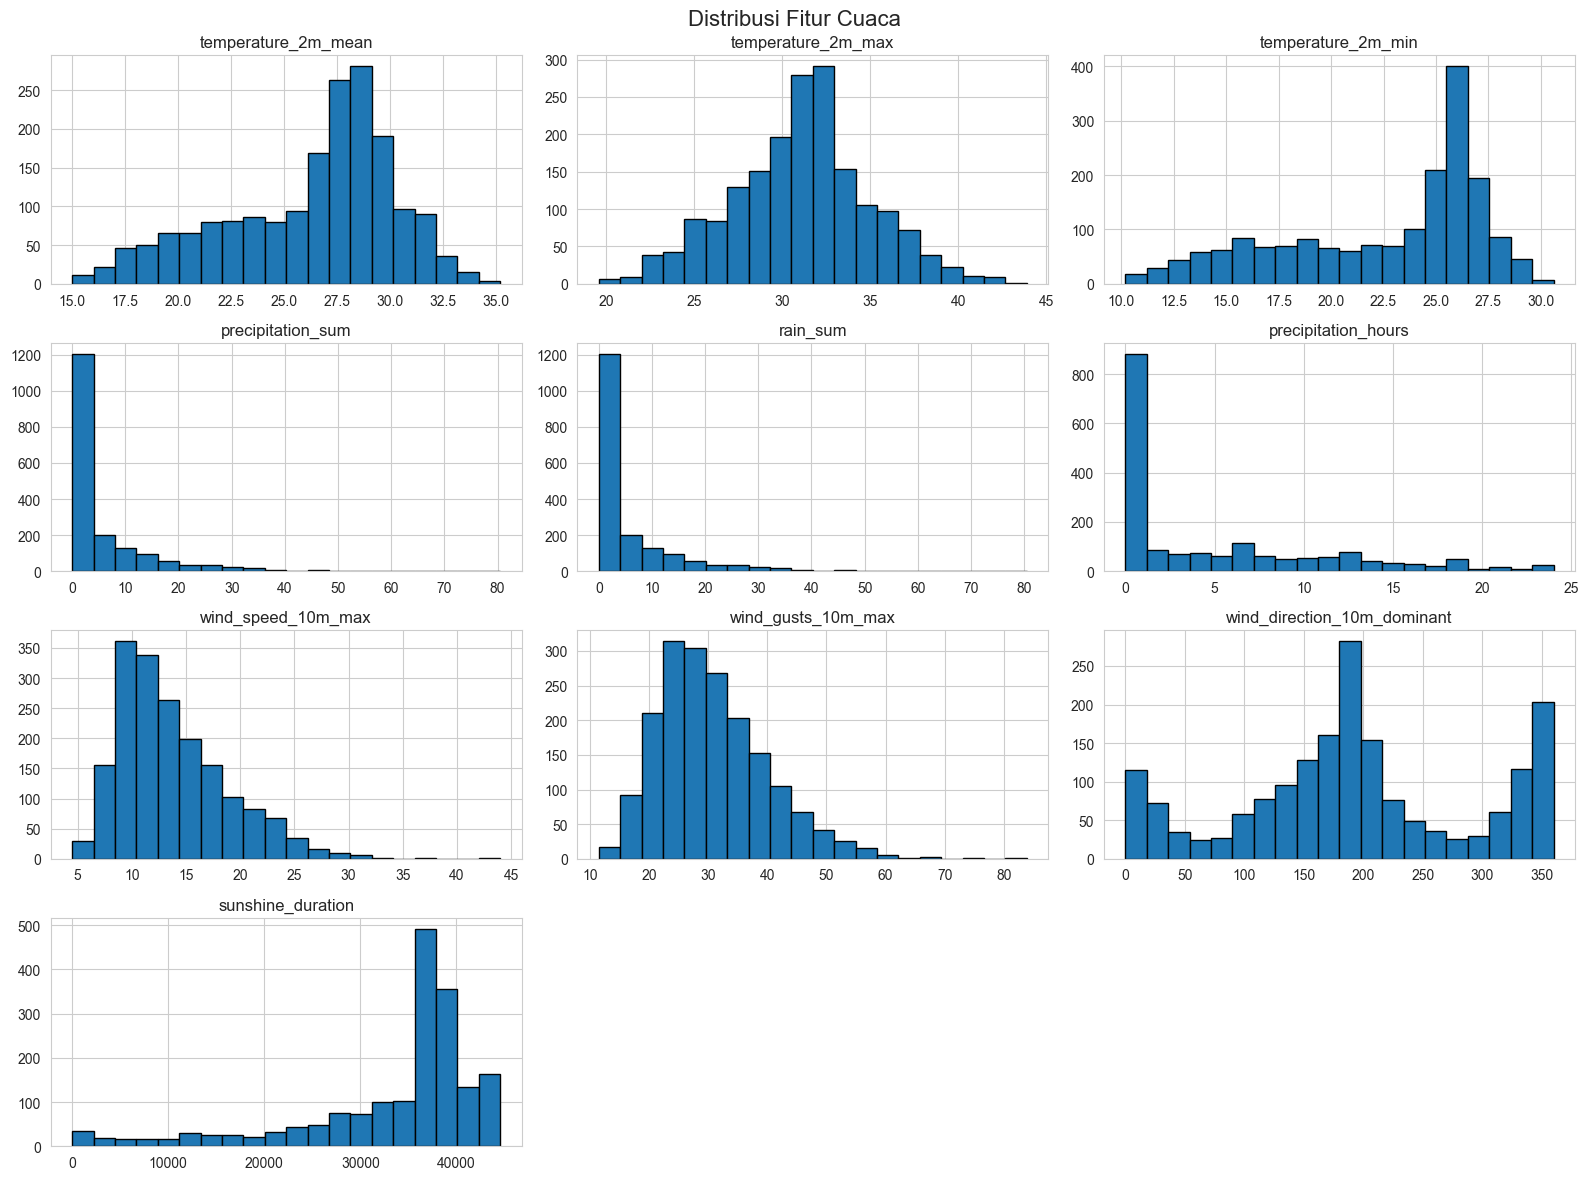

In [16]:
# Distribusi setiap fitur
X.hist(figsize=(16, 12), bins=20, edgecolor='black')

plt.suptitle('Distribusi Fitur Cuaca', fontsize=16)
plt.tight_layout()
plt.show()

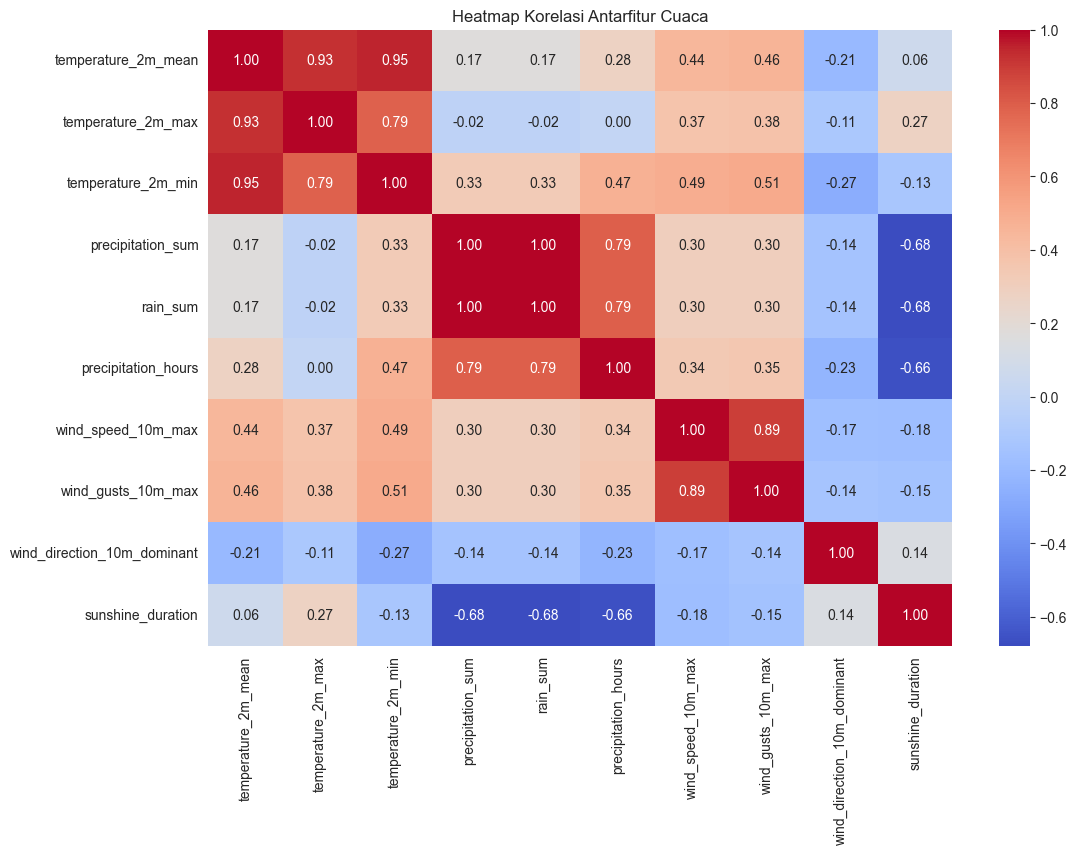

In [17]:
# Korelasi antarfitur
plt.figure(figsize=(12, 8))

sns.heatmap(X.corr(), annot=True, cmap='coolwarm', fmt='.2f')

plt.title('Heatmap Korelasi Antarfitur Cuaca')
plt.show()

In [18]:
# Encoding target menggunakan LabelEncoder
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# Menampilkan hasil encoding
print("Kelas asli:", label_encoder.classes_)
print("Kelas setelah encoding:", np.unique(y_encoded))

Kelas asli: [ 0  1  2  3 51 53 55 61 63 65]
Kelas setelah encoding: [0 1 2 3 4 5 6 7 8 9]


In [19]:
# Membagi data training dan testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

# Menampilkan jumlah data
print("Jumlah data training:", X_train.shape[0])
print("Jumlah data testing:", X_test.shape[0])
print("Jumlah fitur:", X_train.shape[1])

Jumlah data training: 1461
Jumlah data testing: 366
Jumlah fitur: 10


In [20]:
# Import algoritma XGBoost
from xgboost import XGBClassifier

# Membuat model XGBoost Classifier
model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    random_state=42,
    eval_metric='mlogloss'
)

In [21]:
# Melatih model menggunakan data training
model.fit(X_train, y_train)

print("Model XGBoost berhasil dilatih.")

Model XGBoost berhasil dilatih.


In [22]:
# Prediksi data testing
y_pred = model.predict(X_test)

# Prediksi probabilitas setiap kelas
y_proba = model.predict_proba(X_test)

print("Hasil prediksi:", y_pred[:10])
print("Label sebenarnya:", y_test[:10])

Hasil prediksi: [3 8 0 8 4 9 8 0 0 8]
Label sebenarnya: [3 8 3 8 4 8 8 3 0 8]


In [23]:
# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)

recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

# Menampilkan hasil evaluasi
print("Accuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-Score :", round(f1, 4))

Accuracy : 0.6448
Precision: 0.6265
Recall   : 0.6448
F1-Score : 0.6195


In [24]:
# Laporan klasifikasi setiap kelas
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_.astype(str),
    zero_division=0
))

              precision    recall  f1-score   support

           0       0.48      0.63      0.55        46
           1       0.20      0.05      0.08        19
           2       0.50      0.06      0.11        16
           3       0.60      0.70      0.65        81
          51       0.97      0.85      0.90        33
          53       0.68      0.86      0.76        22
          55       0.33      0.12      0.18         8
          61       0.56      0.52      0.54        29
          63       0.73      0.85      0.78        84
          65       0.70      0.50      0.58        28

    accuracy                           0.64       366
   macro avg       0.57      0.51      0.51       366
weighted avg       0.63      0.64      0.62       366



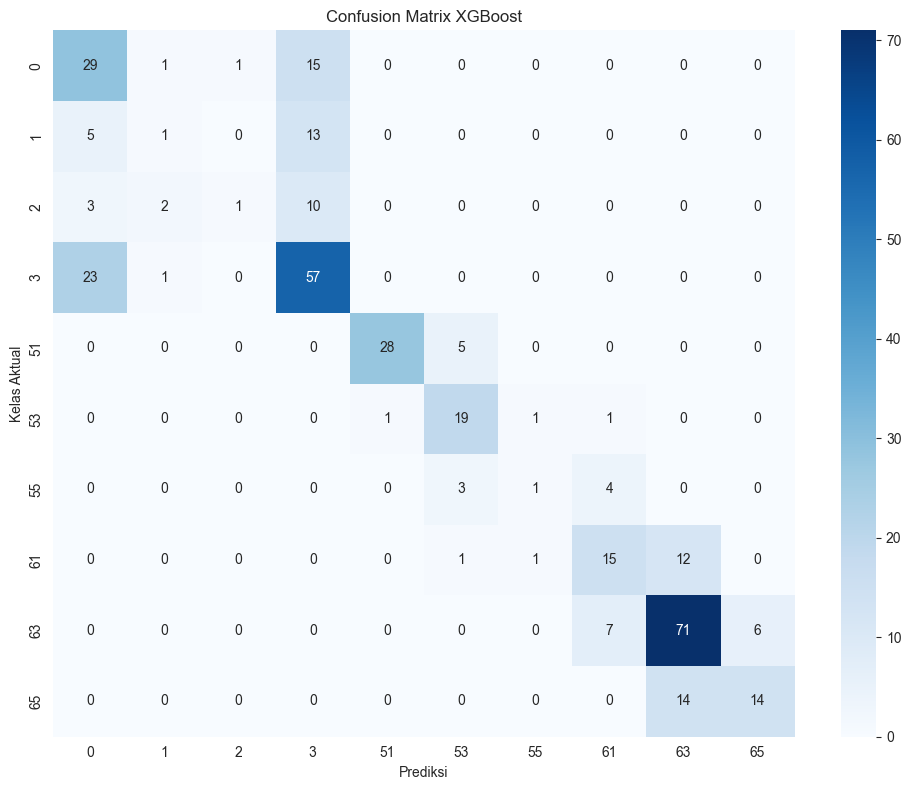

In [25]:
# Confusion Matrix
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title('Confusion Matrix XGBoost')
plt.xlabel('Prediksi')
plt.ylabel('Kelas Aktual')
plt.tight_layout()
plt.show()

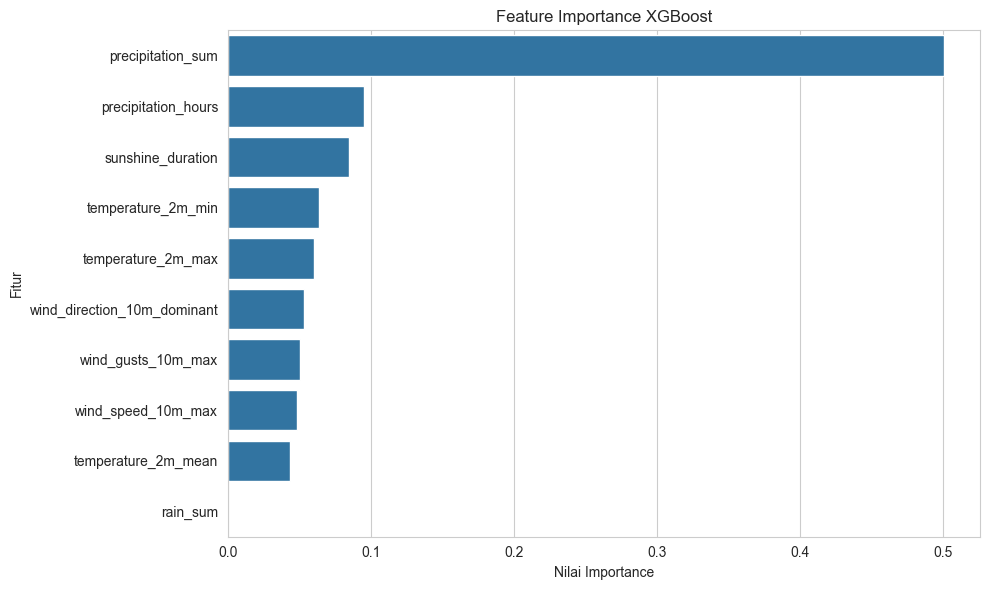

In [26]:
# Feature Importance XGBoost
importance = pd.DataFrame({
    'Fitur': X.columns,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(data=importance, x='Importance', y='Fitur')

plt.title('Feature Importance XGBoost')
plt.xlabel('Nilai Importance')
plt.ylabel('Fitur')
plt.tight_layout()
plt.show()

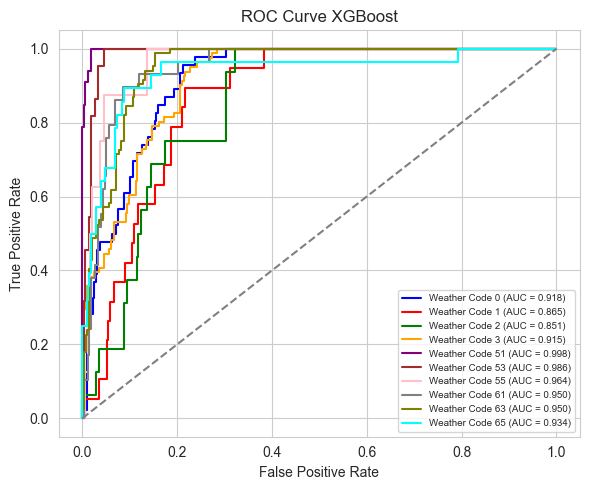

In [27]:
# ROC Curve & AUC Multikelas
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from itertools import cycle

y_test_bin = label_binarize(
    y_test,
    classes=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(6, 5))

colors = cycle(['blue', 'red', 'green', 'orange', 'purple',
                'brown', 'pink', 'gray', 'olive', 'cyan'])

for i, color in zip(range(len(label_encoder.classes_)), colors):
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_proba[:, i])
    auc_score = auc(fpr, tpr)

    plt.plot(
        fpr, tpr,
        color=color,
        label=f'Weather Code {label_encoder.classes_[i]} (AUC = {auc_score:.3f})'
    )

plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve XGBoost')
plt.legend(fontsize=7, loc='lower right')
plt.tight_layout()
plt.show()

In [31]:
# Menghitung metrik evaluasi
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test, y_pred, average='weighted', zero_division=0
)

recall = recall_score(
    y_test, y_pred, average='weighted', zero_division=0
)

f1 = f1_score(
    y_test, y_pred, average='weighted', zero_division=0
)

# Menghitung ROC-AUC
y_proba = model.predict_proba(X_test)

roc_auc = roc_auc_score(
    y_test, y_proba, multi_class='ovr', average='weighted'
)

In [32]:
# Ringkasan metrik evaluasi
hasil_evaluasi = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
    'Nilai': [accuracy, precision, recall, f1, roc_auc]
})

display(hasil_evaluasi)

,Metrik,Nilai
0,Accuracy,0.644809
1,Precision,0.626465
2,Recall,0.644809
3,F1-Score,0.619528
4,ROC-AUC,0.935092
